# データ確認: parquet の行と画像フレームを並べて見る

`data/` 以下の parquet（1行=1フレームの state / action など）を指定し、各行に対応する上方カメラの画像を横に並べて表示する。

LeRobot v3.0 形式では画像は parquet に入っておらず、全エピソードを連結した mp4 に入っている。
parquet の1行に対応する画像は、次の手順で動画から取り出す:

1. 行の `episode_index` から、`meta/episodes` のそのエピソードの行を取り出す
2. そこにある `videos/observation.images.top/from_timestamp`（動画内でのエピソードの開始時刻）に
   `frame_index / fps`（エピソード内での経過時間）を足すと、動画内の時刻になる
3. その時刻のフレームを動画からデコードする

使い方: 「設定」のセルで `PARQUET` を変えて上から順に実行する。
「一覧表示」「1フレームの詳細」は表示したい行を変えてそのセルだけ再実行すればよい。

In [1]:
import base64
import io
import json
from pathlib import Path

import av
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from PIL import Image

# notebooks/ から開いてもリポジトリ直下から開いても同じデータを読めるようにする
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = REPO / "data/aloha_sim_transfer_cube_human"
IMAGE_KEY = "observation.images.top"  # カメラ画像の特徴量名

for f in sorted(DATASET.glob("data/*/*.parquet")):
    print(f.relative_to(DATASET))

data/chunk-000/file-000.parquet
data/chunk-000/file-001.parquet
data/chunk-000/file-002.parquet


## 設定

In [2]:
PARQUET = "data/chunk-000/file-000.parquet"  # 上に表示された中から選ぶ（DATASET からの相対パス）

## 読み込み

指定した parquet と、行と動画を対応づけるためのメタデータ（`meta/`）を読む。

In [3]:
info = json.loads((DATASET / "meta/info.json").read_text())
FPS = info["fps"]
JOINTS = info["features"]["observation.state"]["names"]["motors"]  # 14次元の各関節の名前

episodes = pd.concat(
    [pd.read_parquet(f) for f in sorted(DATASET.glob("meta/episodes/*/*.parquet"))]
).set_index("episode_index")
tasks = pd.read_parquet(DATASET / "meta/tasks.parquet")  # 行の名前がタスク文、列が task_index
TASK_NAMES = dict(zip(tasks["task_index"], tasks.index))

df = pd.read_parquet(DATASET / PARQUET)
print(f"{PARQUET}: {len(df)} 行, 列: {list(df.columns)}")
print(f"通し番号 index: {df['index'].min()} - {df['index'].max()}")

# このファイルに含まれるエピソードと、それぞれのフレームの範囲
# （count が 400 未満なら、そのエピソードは別の parquet にまたがっている）
df.groupby("episode_index")["frame_index"].agg(["min", "max", "count"]).T

data/chunk-000/file-000.parquet: 9200 行, 列: ['observation.state', 'action', 'episode_index', 'frame_index', 'timestamp', 'next.done', 'index', 'task_index']
通し番号 index: 0 - 9199


episode_index,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
min,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
max,399,399,399,399,399,399,399,399,399,399,...,399,399,399,399,399,399,399,399,399,399
count,400,400,400,400,400,400,400,400,400,400,...,400,400,400,400,400,400,400,400,400,400


In [4]:
df.head()

,observation.state,action,episode_index,frame_index,timestamp,next.done,index,task_index
0,"[0.0, -0.96, 1.16, 0.0, -0.3, 0.0, 0.0, 0.0, -...","[-0.013805827, -0.9295924, 1.1796312, -0.00306...",0,0,0.00,False,0,0
1,"[-0.0011429751, -0.9560795, 1.1671464, -0.0019...","[-0.013805827, -0.9127186, 1.1796312, -0.00460...",0,1,0.02,False,1,0
2,"[-0.0027130623, -0.9437811, 1.1754341, -0.0057...","[-0.013805827, -0.90658265, 1.1796312, -0.0030...",0,2,0.04,False,2,0
3,"[-0.004145828, -0.93545496, 1.1806098, -0.0072...","[-0.013805827, -0.90198076, 1.1796312, -0.0030...",0,3,0.06,False,3,0
4,"[-0.0054008896, -0.9286405, 1.1829095, -0.0069...","[-0.013805827, -0.9004468, 1.1811652, -0.00306...",0,4,0.08,False,4,0


## state と action の中身

どちらも長さ 14 のベクトルで、要素の並びは同じ:
`[左腕 6関節, 左グリッパー, 右腕 6関節, 右グリッパー]`（インデックス 6 と 13 がグリッパー）。

| 要素 | 意味 |
|---|---|
| `observation.state` | そのフレームでのロボット（パペットアーム）の**現在の関節角**。シミュレータでは `env.step()` が返す `agent_pos`（gym-aloha の `qpos`）にあたる |
| `action` | そのフレームで指令した**目標関節角**。人間がリーダーアームを動かして遠隔操作したデモなので、操作者が指令した位置が入っている。シミュレータの `env.step(action)` にそのまま渡せる |

時刻 t では、`state[t]` を観測した状態で `action[t]` を指令した、という対応になっている。
ロボットは目標を追いかけて動くので、state は action より少し遅れて同じような動きをする（下の「1フレームの詳細」のグラフで確認できる）。

### 各要素（片腕あたり 7 個。左腕は `left_`、右腕は `right_` が付く）

| インデックス（左 / 右） | 名前 | 単位 | 動き |
|---|---|---|---|
| 0 / 7 | `waist` | rad | 腕全体を土台ごと鉛直軸まわりに回す（左右に振る） |
| 1 / 8 | `shoulder` | rad | 肩で上腕を上げ下げする |
| 2 / 9 | `elbow` | rad | 肘で前腕を曲げ伸ばしする |
| 3 / 10 | `forearm_roll` | rad | 前腕をその長さ方向の軸まわりにひねる |
| 4 / 11 | `wrist_angle` | rad | 手首を上下に曲げる（ピッチ） |
| 5 / 12 | `wrist_rotate` | rad | 手首から先を回す（ロール） |
| 6 / 13 | `gripper` | 正規化値 | グリッパーの開き具合。0 = 閉, 1 = 開 |

- 腕の 6 関節は**関節角そのもの（絶対値, ラジアン）**。すべて 0 のときが基準姿勢で、各エピソードの先頭フレームは左右とも `[0, -0.96, 1.16, 0, -0.3, 0]`（ACT / gym-aloha の `START_ARM_POSE`）。
- グリッパーは**指の位置を 0〜1 に正規化した値**。シミュレータの指の位置（閉 0.01844 m 〜 開 0.05800 m）を
  `(x - 0.01844) / (0.05800 - 0.01844)` で変換している。
  action のグリッパー値は目標値なので、1 を少し超えることがある（このデータセットでは約 0.14〜1.2）。
  キューブをつかんでいる間は、指令（action, 約 0.2）より実際の開き（state, 約 0.6）のほうが大きいまま止まる（キューブに当たってそれ以上閉じられないため）。開く側も、action が 1 を超えても state は 1 付近で頭打ちになる。
  また、各エピソードの先頭フレーム（frame_index = 0）だけはグリッパーの state が 0.00 になっている。
- ロボットは Trossen Robotics の ViperX 300 6DOF（左右 2 台）。関節の名前と可動範囲は下のリンクの仕様ページにある。

### 参照先

- データセット（関節名 `names.motors` は `meta/info.json` に記載）:
  [lerobot/aloha_sim_transfer_cube_human](https://huggingface.co/datasets/lerobot/aloha_sim_transfer_cube_human) /
  [meta/info.json](https://huggingface.co/datasets/lerobot/aloha_sim_transfer_cube_human/blob/main/meta/info.json)
- シミュレータ gym-aloha（行動空間・観測空間の説明は README と `gym_aloha/tasks/sim.py` 冒頭のコメント、グリッパーの定数と正規化は `gym_aloha/constants.py`）:
  [README](https://github.com/huggingface/gym-aloha) /
  [tasks/sim.py](https://github.com/huggingface/gym-aloha/blob/main/gym_aloha/tasks/sim.py) /
  [constants.py](https://github.com/huggingface/gym-aloha/blob/main/gym_aloha/constants.py)
- ACT の元実装（同じ定義。`sim_env.py` 冒頭のコメントと `constants.py`）:
  [tonyzhaozh/act](https://github.com/tonyzhaozh/act) /
  [sim_env.py](https://github.com/tonyzhaozh/act/blob/main/sim_env.py) /
  [constants.py](https://github.com/tonyzhaozh/act/blob/main/constants.py)
- ACT / ALOHA の論文: [Learning Fine-Grained Bimanual Manipulation with Low-Cost Hardware (arXiv:2304.13705)](https://arxiv.org/abs/2304.13705)、
  プロジェクトページ: [tonyzhaozh.github.io/aloha](https://tonyzhaozh.github.io/aloha/)
- ロボットアームの仕様（関節と可動範囲）: [ViperX-300 6DOF — Interbotix X-Series Arms Documentation](https://docs.trossenrobotics.com/interbotix_xsarms_docs/specifications/vx300s.html)

In [ ]:
# この parquet での各要素の値の範囲
state = np.stack(df["observation.state"].to_numpy())
action = np.stack(df["action"].to_numpy())
pd.DataFrame(
    {
        "state min": state.min(0),
        "state max": state.max(0),
        "action min": action.min(0),
        "action max": action.max(0),
    },
    index=pd.Index(JOINTS, name="joint"),
).round(3)

## 画像を取り出す関数

In [5]:
_containers = {}  # 開いた動画ファイルを使い回す（毎回開き直すと遅い）


def video_path(episode: int) -> Path:
    # このエピソードが入っている mp4 のパス（meta/episodes の chunk_index / file_index から決まる）
    ep = episodes.loc[episode]
    return DATASET / info["video_path"].format(
        video_key=IMAGE_KEY,
        chunk_index=ep[f"videos/{IMAGE_KEY}/chunk_index"],
        file_index=ep[f"videos/{IMAGE_KEY}/file_index"],
    )


def video_time(row: pd.Series) -> float:
    # parquet の1行に対応する動画内の時刻（秒）= エピソードの開始時刻 + エピソード内の経過時間
    start = episodes.loc[row["episode_index"], f"videos/{IMAGE_KEY}/from_timestamp"]
    return start + row["frame_index"] / FPS


def read_frame(row: pd.Series) -> np.ndarray:
    # parquet の1行に対応する画像 (480, 640, 3) uint8 を動画から取り出す
    path = video_path(row["episode_index"])
    if path not in _containers:
        _containers[path] = av.open(str(path))
    container = _containers[path]
    stream = container.streams.video[0]
    t = video_time(row)
    # シークは手前のキーフレームに飛ぶので、そこから目的の時刻までデコードを進める。
    # 浮動小数の誤差で目的のフレームを飛ばさないよう、半フレーム分の余裕を持たせる
    container.seek(int(t / stream.time_base), stream=stream)
    for frame in container.decode(stream):
        if frame.time >= t - 0.5 / FPS:
            return frame.to_ndarray(format="rgb24")
    raise ValueError(f"{path} に時刻 {t:.3f} s のフレームがない")


def img_tag(image: np.ndarray, width: int) -> str:
    # 画像を HTML の <img> タグにする（表の中に埋め込むため）
    h, w, _ = image.shape
    buf = io.BytesIO()
    Image.fromarray(image).resize((width, h * width // w)).save(buf, format="PNG")
    return f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}">'


def fmt_vec(v) -> str:
    # 14次元のベクトルを「左腕 7 / 右腕 7」の2行に分けて表示する
    left, right = (" ".join(f"{x:+.3f}" for x in half) for half in (v[:7], v[7:]))
    return f"<code>L: {left}<br>R: {right}</code>"

## 一覧表示: 複数の行を画像付きで並べる

`ROWS` に表示したい行を指定する（`df` を絞り込んだ DataFrame）。1行ごとに動画をデコードするので、数十行程度にしておく。

- `video_time`: その行の画像を取り出した動画内の時刻（秒）
- `state` / `action`: 14次元を左腕（L）と右腕（R）に分けて表示。各腕は waist, shoulder, elbow, forearm_roll, wrist_angle, wrist_rotate, gripper の順

image,index,episode,frame,timestamp,video_time,next.done,state,action
,0,0,0,0.00,0.00,False,L: +0.000 -0.960 +1.160 +0.000 -0.300 +0.000 +0.000R: +0.000 -0.960 +1.160 +0.000 -0.300 +0.000 +0.000,L: -0.014 -0.930 +1.180 -0.003 -0.330 -0.002 +0.164R: +0.011 -0.930 +1.203 -0.002 -0.319 +0.015 +0.190
,50,0,50,1.00,1.00,False,L: -0.014 -0.810 +1.193 -0.008 -0.401 +0.002 +0.164R: -0.057 -0.601 +1.194 +0.010 -0.195 +0.027 +0.277,L: -0.014 -0.805 +1.190 -0.006 -0.410 +0.002 +0.164R: -0.071 -0.565 +1.193 +0.012 -0.219 +0.028 +0.482
,100,0,100,2.00,2.00,False,L: -0.014 -0.804 +1.214 -0.023 -0.401 -0.004 +0.165R: -0.034 -0.068 +1.045 +0.000 -0.331 +0.034 +0.969,L: -0.014 -0.805 +1.210 -0.020 -0.410 -0.005 +0.164R: -0.034 -0.051 +1.043 +0.014 -0.298 +0.061 +1.085
,150,0,150,3.00,3.00,False,L: -0.014 -0.805 +1.215 -0.023 -0.401 -0.006 +0.165R: -0.094 -0.172 +1.070 -0.003 -0.251 +0.045 +0.971,L: -0.014 -0.804 +1.212 -0.020 -0.410 -0.006 +0.164R: -0.126 -0.143 +1.068 -0.002 -0.273 +0.044 +1.048
,200,0,200,4.00,4.00,False,L: -0.014 -0.804 +1.215 -0.026 -0.402 -0.009 +0.165R: -0.126 -0.030 +1.041 -0.007 -0.282 +0.043 +0.605,L: -0.014 -0.801 +1.212 -0.029 -0.416 -0.009 +0.164R: -0.126 -0.071 +1.037 -0.009 -0.288 +0.038 +0.210
,250,0,250,5.00,5.00,False,L: -0.017 -0.328 +0.889 -0.126 -0.542 -0.096 +0.893R: -0.078 -0.347 +0.865 -0.398 -0.558 -0.824 +0.636,L: -0.026 -0.295 +0.870 -0.121 -0.568 -0.097 +1.085R: -0.078 -0.310 +0.853 -0.385 -0.583 -0.824 +0.210
,300,0,300,6.00,6.00,False,L: -0.042 -0.149 +0.752 -0.140 -0.618 -0.117 +0.925R: -0.095 -0.138 +0.742 -0.420 -0.708 -0.828 +0.673,L: -0.043 -0.149 +0.749 -0.124 -0.627 -0.112 +0.376R: -0.098 -0.138 +0.738 -0.385 -0.729 -0.824 +0.214
,350,0,350,7.00,7.00,False,L: -0.019 -0.464 +0.992 -0.130 -0.463 +0.009 +0.861R: -0.078 -0.373 +0.896 -0.093 -0.387 +0.161 +0.888,L: -0.014 -0.505 +0.996 -0.123 -0.474 +0.017 +0.305R: -0.077 -0.414 +0.911 -0.091 -0.413 +0.166 +0.874

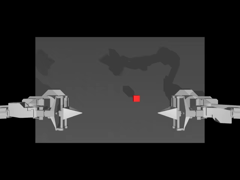
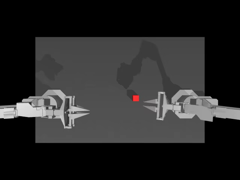
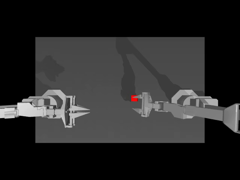
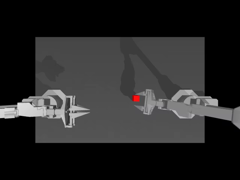
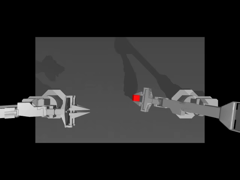
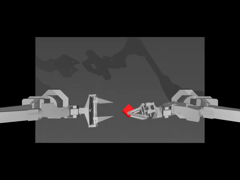
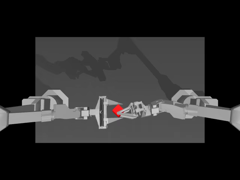
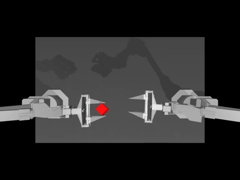

In [6]:
# 例: df.iloc[0:10]                                      … 先頭の 10 行
#     df[df["episode_index"] == 3].iloc[::50]            … エピソード 3 を 50 フレームおき
#     df[df["next.done"]]                                … 各エピソードの最後のフレーム
ROWS = df[df["episode_index"] == df["episode_index"].iloc[0]].iloc[::50]


def show_table(rows: pd.DataFrame, width: int = 240) -> None:
    table = pd.DataFrame(
        {
            "image": [img_tag(read_frame(r), width) for _, r in rows.iterrows()],
            "index": rows["index"],
            "episode": rows["episode_index"],
            "frame": rows["frame_index"],
            "timestamp": rows["timestamp"].map("{:.2f}".format),
            "video_time": [f"{video_time(r):.2f}" for _, r in rows.iterrows()],
            "next.done": rows["next.done"],
            "state": rows["observation.state"].map(fmt_vec),
            "action": rows["action"].map(fmt_vec),
        }
    )
    display(HTML(table.to_html(escape=False, index=False)))


show_table(ROWS)

## 1フレームの詳細

`ROW`（`PARQUET` の中での行番号、0 始まり）の1行について、画像と関節ごとの値を横に並べて表示する。
下のグラフは同じエピソードの関節角の時系列で、縦線が今見ているフレーム。


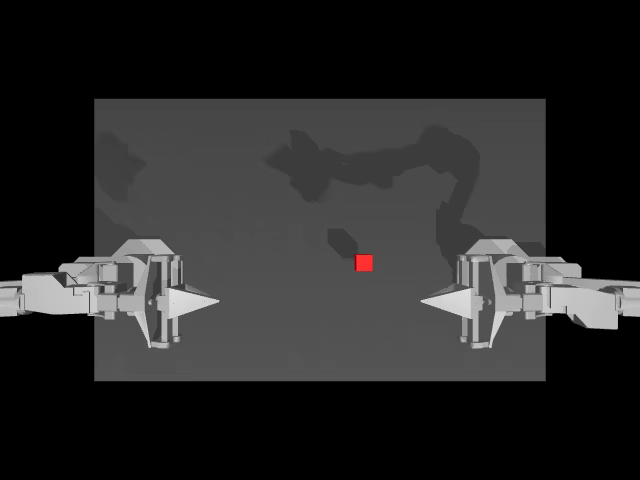

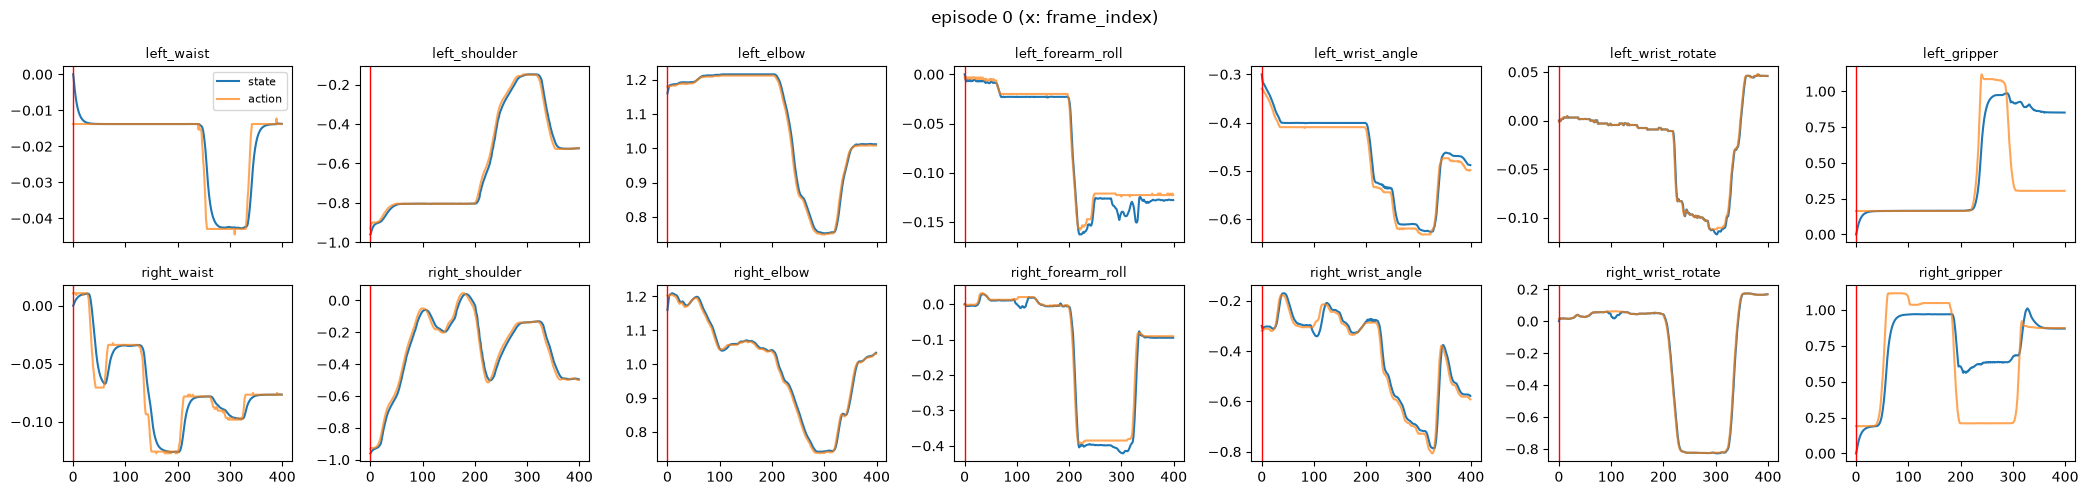

In [7]:
ROW = 0  # PARQUET の中での行番号（0 始まり）


def show_detail(row: pd.Series) -> None:
    meta = pd.Series(
        {
            "parquet": PARQUET,
            "index": row["index"],
            "episode_index": row["episode_index"],
            "frame_index": row["frame_index"],
            "timestamp": f"{row['timestamp']:.3f}",
            "next.done": row["next.done"],
            "task": TASK_NAMES[row["task_index"]],
            "video": video_path(row["episode_index"]).relative_to(DATASET),
            "video_time": f"{video_time(row):.3f}",
        }
    ).to_frame("value")
    joints = pd.DataFrame(
        {
            "state": row["observation.state"],
            "action": row["action"],
            "action - state": row["action"] - row["observation.state"],
        },
        index=JOINTS,
    ).map("{:+.4f}".format)

    display(
        HTML(
            '<div style="display: flex; gap: 24px; align-items: flex-start">'
            f"<div>{img_tag(read_frame(row), 640)}</div>"
            f"<div>{meta.to_html()}<br>{joints.to_html()}</div>"
            "</div>"
        )
    )


def plot_episode(row: pd.Series) -> None:
    ep = df[df["episode_index"] == row["episode_index"]]
    state = np.stack(ep["observation.state"].to_numpy())
    action = np.stack(ep["action"].to_numpy())
    fig, axes = plt.subplots(2, 7, figsize=(21, 5), sharex=True)
    for j, ax in enumerate(axes.flat):
        ax.plot(ep["frame_index"], state[:, j], label="state")
        ax.plot(ep["frame_index"], action[:, j], label="action", alpha=0.7)
        ax.axvline(row["frame_index"], color="red", lw=1)
        ax.set_title(JOINTS[j], fontsize=9)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"episode {row['episode_index']} (x: frame_index)")
    fig.tight_layout()
    plt.show()


row = df.iloc[ROW]
show_detail(row)
plot_episode(row)